**Setup**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!git clone https://github.com/facebookresearch/sam2.git
%cd sam2
!pip install -e ".[notebooks]"

# Download hiera_tiny (2.1) checkpoint — smallest/fastest, matches your plan
!cd checkpoints && wget https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt

Cloning into 'sam2'...
remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 1107 (delta 13), reused 7 (delta 7), pack-reused 1089 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 30.43 MiB/s, done.
Resolving deltas: 100% (385/385), done.
/content/sam2
Obtaining file:///content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 81.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 68.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import torch
major = torch.cuda.get_device_properties(0).major
autocast_dtype = torch.bfloat16 if major >= 8 else torch.float16   # T4 → fp16
torch.autocast(device_type="cuda", dtype=autocast_dtype).__enter__()
if major >= 8:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

**Image Mode**

In [ ]:
import cv2

# 1. Define the exact path to your image in Google Drive
image_path = "/content/drive/MyDrive/Sam2/test_image.jpeg"

# 2. Load the image using OpenCV
bgr_image = cv2.imread(image_path)

# 3. Convert it from BGR (OpenCV default) to RGB (SAM 2 requires RGB)
your_image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)

print("Image successfully loaded! Shape:", your_image.shape)


Image successfully loaded! Shape: (1000, 563, 3)


In [ ]:
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# Build the model
sam2_model = build_sam2("configs/sam2.1/sam2.1_hiera_t.yaml", "checkpoints/sam2.1_hiera_tiny.pt", device="cuda")
predictor = SAM2ImagePredictor(sam2_model)

# Set the image we just loaded from Google Drive
predictor.set_image(your_image)

# Choose a pixel coordinate to select your object (e.g., Pixel X=300, Pixel Y=400)
# Make sure these numbers fit within your image dimensions!
x = 320
y = 500

# Predict the mask
masks, scores, _ = predictor.predict(
    point_coords=[[x, y]],
    point_labels=[1]  # 1 means "foreground click" (include this object)
)

print(f"Successfully generated {len(masks)} mask options!")


Successfully generated 3 mask options!


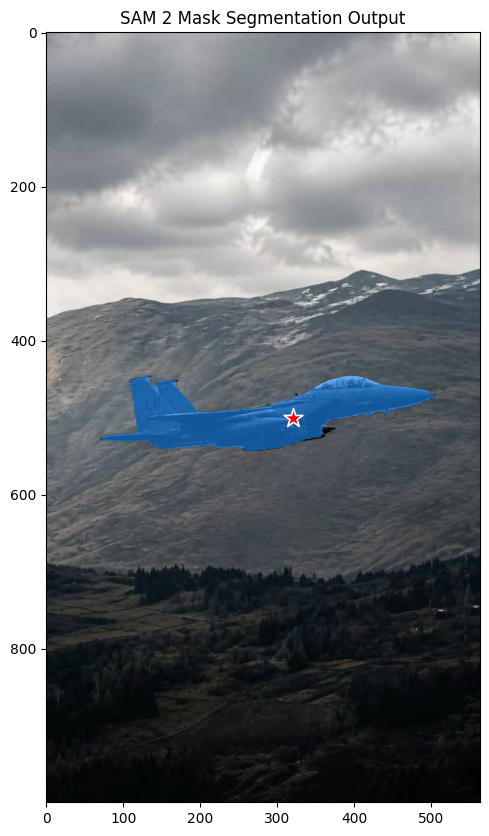

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Set up the plotting window
plt.figure(figsize=(10, 10))
plt.imshow(your_image)

# 2. Pick the best mask out of the 3 options (index 0 is usually the primary choice)
best_mask = masks[0]

# 3. Create a semi-transparent blue color overlay for the mask
# [Red, Green, Blue, Alpha/Opacity] -> 0.6 means 60% translucent blue
color = np.array([30/255, 144/255, 255/255, 0.6])

# 4. Reshape and apply the color overlay to the mask areas
h, w = best_mask.shape[-2:]
mask_image = best_mask.reshape(h, w, 1) * color.reshape(1, 1, -1)

# 5. Display the mask overlay and plot your click point
plt.gca().imshow(mask_image)
plt.gca().scatter(x, y, color='red', marker='*', s=200, edgecolor='white', linewidth=1.2, label='Your Click')

plt.title("SAM 2 Mask Segmentation Output")
plt.axis('on') # Kept 'on' so you can see the pixel numbers on the border
plt.show()


**Video mode**

In [ ]:
from sam2.build_sam import build_sam2_video_predictor

# Initialize the video predictor
predictor = build_sam2_video_predictor(
    "configs/sam2.1/sam2.1_hiera_t.yaml",
    "checkpoints/sam2.1_hiera_tiny.pt",
    device="cuda"
)

# Target path to your Google Drive video
video_path = "/content/drive/MyDrive/Sam2/juggle.mp4"

# Load the frames into memory state
inference_state = predictor.init_state(video_path=video_path)
print("Successfully loaded video! Total frames:", len(inference_state["images"]))


Successfully loaded video! Total frames: 277


In [ ]:
# Exact coordinates for the soccer ball center on frame 0
ball_x = 408
ball_y = 635

# Assign a tracked ID of 1 to the soccer ball
obj_id = 1

# Send the initial tracking point to SAM 2
_, out_obj_ids, out_mask_logits = predictor.add_new_points_or_box(
    inference_state=inference_state,
    frame_idx=0,
    obj_id=obj_id,
    points=[[ball_x, ball_y]],
    labels=[1], # 1 means foreground inclusion
)

print(f"Tracking initiated for object ID: {out_obj_ids}")

Tracking initiated for object ID: [1]


/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(


In [ ]:
import numpy as np

print("Propagating masks across all 277 frames. Please wait...")

# Dictionary to hold our final tracking results for visualization later
video_segments = {}

with torch.inference_mode():
    for frame_idx, obj_ids, mask_logits in predictor.propagate_in_video(inference_state):
      # Convert raw model output logits to a simple binary True/False mask array
      # mask_logits shape is usually (number_of_objects, height, width)
      # We take [0] because we are only tracking 1 object (the ball)
      binary_mask = (mask_logits[0] > 0.0).cpu().numpy()

      # Store the mask for this frame
      video_segments[frame_idx] = binary_mask

      # Print out progress indicators every 15 frames so you know it's working
      if frame_idx % 15 == 0 or frame_idx == 276:
          print(f"📊 Completed tracking up to frame {frame_idx}/276")

print("\n🎉 Tracking propagation complete! All masks are calculated.")

Propagating masks across all 277 frames. Please wait...


propagate in video:   0%|          | 0/277 [00:00<?, ?it/s]

📊 Completed tracking up to frame 0/276


propagate in video:   6%|▌         | 17/277 [00:02<00:36,  7.10it/s]

📊 Completed tracking up to frame 15/276


...

📊 Completed tracking up to frame 255/276


propagate in video:  98%|█████████▊| 272/277 [00:39<00:00,  6.59it/s]

📊 Completed tracking up to frame 270/276


propagate in video: 100%|██████████| 277/277 [00:40<00:00,  6.80it/s]

📊 Completed tracking up to frame 276/276

🎉 Tracking propagation complete! All masks are calculated.


In [ ]:
import cv2
import numpy as np

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

out_path = "/content/drive/MyDrive/Sam2/juggle_tracked.mp4"
writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

frame_idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    if frame_idx in video_segments:
        mask = video_segments[frame_idx].squeeze()
        mask = cv2.resize(mask.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
        color = np.array([30, 144, 255], dtype=np.uint8)
        frame[mask] = (frame[mask] * 0.5 + color * 0.5).astype(np.uint8)
    writer.write(frame)
    frame_idx += 1

cap.release()
writer.release()
print("Saved:", out_path)

Saved: /content/drive/MyDrive/Sam2/juggle_tracked.mp4


In [ ]:
from IPython.display import Video
Video(out_path, embed=True, width=400)

In [ ]:
np.savez_compressed(
    "/content/drive/MyDrive/Sam2/juggle_masks.npz",
    **{f"frame_{k}": v.squeeze() for k, v in video_segments.items()}
)
print("Masks saved to Drive")

**Other**

Actual frame size (w,h): 720 1280


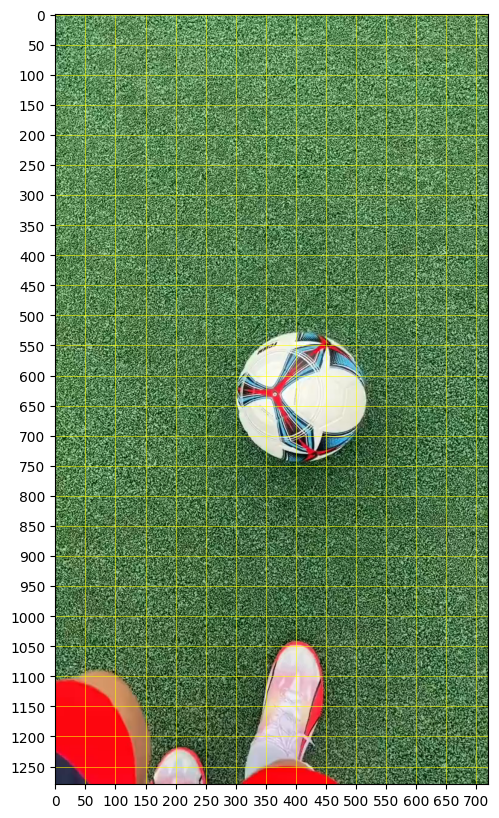

In [ ]:
import cv2, matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)
ret, frame0 = cap.read()
cap.release()
frame0_rgb = cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB)
h, w = frame0_rgb.shape[:2]
print("Actual frame size (w,h):", w, h)

plt.figure(figsize=(6,10))
plt.imshow(frame0_rgb)
plt.xticks(range(0, w, 50)); plt.yticks(range(0, h, 50))
plt.grid(color='yellow', linewidth=0.4)
plt.show()